In [1]:
from collections import defaultdict, Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
#df_input= pd.read_csv("bitcoin_tweets1000000.csv", encoding="latin1")

In [2]:
df_cluster= pd.read_csv("user_clusters.csv", encoding="latin1")

In [3]:
import numpy as np

def parse_embedding(text):
    text = text.strip()[1:-1]  # Klammern entfernen
    nums = text.split()        # per Leerzeichen splitten
    return np.array(nums, dtype=np.float32)

In [4]:
df_results= pd.read_csv("results.csv",encoding="latin1")

C:\Users\johan\AppData\Local\Temp\ipykernel_1468\257739667.py:1: DtypeWarning: Columns (0,5,6,7,8,13) have mixed types. Specify dtype option on import or set low_memory=False.
  df_results= pd.read_csv("results.csv",encoding="latin1")


In [5]:
df_results.columns

Index(['Unnamed: 0', 'user_name', 'user_location', 'user_description',
       'user_created', 'user_followers', 'user_friends', 'user_favourites',
       'user_verified', 'date', 'text', 'hashtags', 'source', 'is_retweet',
       'cleanText', 'Polarity Score', 'sentiment', 'combined_text',
       'embedding'],
      dtype='object')

In [6]:
df = df_results.merge(df_cluster, on="user_name", how="inner")

In [7]:
df.columns

Index(['Unnamed: 0', 'user_name', 'user_location', 'user_description',
       'user_created', 'user_followers', 'user_friends', 'user_favourites',
       'user_verified', 'date', 'text', 'hashtags', 'source', 'is_retweet',
       'cleanText', 'Polarity Score', 'sentiment', 'combined_text',
       'embedding', 'cluster'],
      dtype='object')

In [8]:
len(df)

515111

In [ ]:
"""import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import numpy as np
import ast

df_tmp = df[["user_name", "cluster"]]  # kleines DF

chunksize = 10_000   # sehr RAM-sicher
first = True
writer = None

for chunk in pd.read_csv(
    "results.csv",
    encoding="latin1",
    chunksize=chunksize,
    usecols=["user_name", "user_description", "embedding", "cleanText"],
    low_memory=True
):
    # Nur die vorhandenen user_name behalten
    merged = chunk.merge(df_tmp, on="user_name", how="inner")

    # Embeddings sicher in float32 umwandeln
    merged["embedding"] = merged["embedding"].apply(parse_embedding)

    # DataFrame → Arrow Table
    table = pa.Table.from_pandas(merged, preserve_index=False)

    if first:
        writer = pq.ParquetWriter("merged_all.parquet", table.schema)
        first = False

    # Jede Tabelle als kleine Rowgroup schreiben
    writer.write_table(table, row_group_size=5000)

    del merged
    del table

if writer:
    writer.close()"""

In [ ]:
"""df_embeding = pd.concat(
    (pd.read_parquet(f) for f in out_files),
    ignore_index=True
)"""

In [11]:
# Aggregation dictionaries
tweet_count       = defaultdict(int)
sum_length        = defaultdict(int)
unique_words      = defaultdict(set)
hashtag_counter   = defaultdict(Counter)
word_counter      = defaultdict(Counter)
retweet_counter   = defaultdict(int)
polarity_sum      = defaultdict(float)
sentiment_counter = defaultdict(Counter)
example_tweet     = {}
user_meta         = {}

In [10]:
def top_n(counter, n=10):
    return [w for w, _ in counter.most_common(n)]

In [12]:
for i, row in df.iterrows():
    user = row["user_name"]
    txt  = str(row["cleanText"])
    cluster = row["cluster"]

    # --- Basisdaten ---
    tweet_count[user] += 1
    sum_length[user]  += len(txt)

    # unique words
    unique_words[user].update(txt.split())

    # hashtags
    hashtags_raw = row["hashtags"]

    if isinstance(hashtags_raw, str):
        hashtags_list = [h for h in hashtags_raw.split()]
    else:
        hashtags_list = []

    for ht in hashtags_list:
        hashtag_counter[user][ht] += 1

    # retweets
    if row["is_retweet"]:
        retweet_counter[user] += 1

    # sentiment
    polarity_sum[user] += row["Polarity Score"]
    sentiment_counter[user][row["sentiment"]] += 1

    # Beispiel-Tweet speichern (nur 1)
    if user not in example_tweet:
        example_tweet[user] = txt

    # user_meta speichern (einmal pro User)
    if user not in user_meta:
        user_meta[user] = {
            "user_location": row["user_location"],
            "user_description": row["user_description"],
            "user_followers": row["user_followers"],
            "user_friends": row["user_friends"],
            "user_favourites": row["user_favourites"],
            "user_verified": row["user_verified"]
        }

In [13]:
usernames = list(tweet_count.keys())

In [14]:
cluster_of_user = df.groupby("user_name")["cluster"].first().to_dict()

In [15]:
labels = [cluster_of_user[u] for u in usernames]

In [16]:
df.columns

Index(['Unnamed: 0', 'user_name', 'user_location', 'user_description',
       'user_created', 'user_followers', 'user_friends', 'user_favourites',
       'user_verified', 'date', 'text', 'hashtags', 'source', 'is_retweet',
       'cleanText', 'Polarity Score', 'sentiment', 'combined_text',
       'embedding', 'cluster'],
      dtype='object')

In [17]:
rows = []

for user in usernames:
    n = tweet_count[user]

    row = {
        "user_name": user,
        "cluster": cluster_of_user[user],

        # ---- META ----
        **user_meta[user],

        # ---- STATISTIK ----
        "tweet_count": n,
        "avg_tweet_length": sum_length[user] / n,
        "unique_words_count": len(unique_words[user]),
        "hashtags_per_tweet": sum(hashtag_counter[user].values()) / n,
        "retweet_rate": retweet_counter[user] / n,

        # ---- SENTIMENT ----
        "polarity_mean": polarity_sum[user] / n,
        "sentiment_distribution": dict(sentiment_counter[user]),

        # ---- INHALT ----
        "top_hashtags": sorted(hashtag_counter[user], key=hashtag_counter[user].get, reverse=True)[:10],
        "example_tweet": example_tweet[user],
    }

    rows.append(row)

df_cluster_evaluation = pd.DataFrame(rows)

In [18]:
df_cluster_evaluation.columns

Index(['user_name', 'cluster', 'user_location', 'user_description',
       'user_followers', 'user_friends', 'user_favourites', 'user_verified',
       'tweet_count', 'avg_tweet_length', 'unique_words_count',
       'hashtags_per_tweet', 'retweet_rate', 'polarity_mean',
       'sentiment_distribution', 'top_hashtags', 'example_tweet'],
      dtype='object')

In [19]:
features = [
    'user_followers', 'user_friends', 'user_favourites', 'user_verified',
    'tweet_count', 'avg_tweet_length', 'unique_words_count',
    'hashtags_per_tweet', 'retweet_rate', 'polarity_mean'
]

In [20]:
log_features = {
    'user_followers',
    'user_friends',
    'user_favourites',
    'tweet_count'
}

In [21]:
df_cluster_evaluation["user_followers"] = pd.to_numeric(
    df_cluster_evaluation["user_followers"],
    errors="coerce"
)
df_cluster_evaluation["user_friends"] = pd.to_numeric(
    df_cluster_evaluation["user_friends"],
    errors="coerce"
)
df_cluster_evaluation["user_favourites"] = pd.to_numeric(
    df_cluster_evaluation["user_favourites"],
    errors="coerce"
)
df_cluster_evaluation["tweet_count"] = pd.to_numeric(
    df_cluster_evaluation["tweet_count"],
    errors="coerce"
)
df_cluster_evaluation["user_verified"] = pd.to_numeric(
    df_cluster_evaluation["user_verified"],
    errors="coerce"
)
df_cluster_evaluation["avg_tweet_length"] = pd.to_numeric(
    df_cluster_evaluation["avg_tweet_length"],
    errors="coerce"
)
df_cluster_evaluation["unique_words_count"] = pd.to_numeric(
    df_cluster_evaluation["unique_words_count"],
    errors="coerce"
)
df_cluster_evaluation["hashtags_per_tweet"] = pd.to_numeric(
    df_cluster_evaluation["hashtags_per_tweet"],
    errors="coerce"
)
df_cluster_evaluation["retweet_rate"] = pd.to_numeric(
    df_cluster_evaluation["retweet_rate"],
    errors="coerce"
)
df_cluster_evaluation["polarity_mean"] = pd.to_numeric(
    df_cluster_evaluation["polarity_mean"],
    errors="coerce"
)

C:\Users\johan\AppData\Local\Temp\ipykernel_1468\1837533757.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data_per_cluster, labels=clusters)
C:\Users\johan\AppData\Local\Temp\ipykernel_1468\1837533757.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data_per_cluster, labels=clusters)
C:\Users\johan\AppData\Local\Temp\ipykernel_1468\1837533757.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data_per_cluster, labels=clusters)
C:\Users\johan\AppData\Local\Temp\ipykernel_1468\1837533757.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been rename

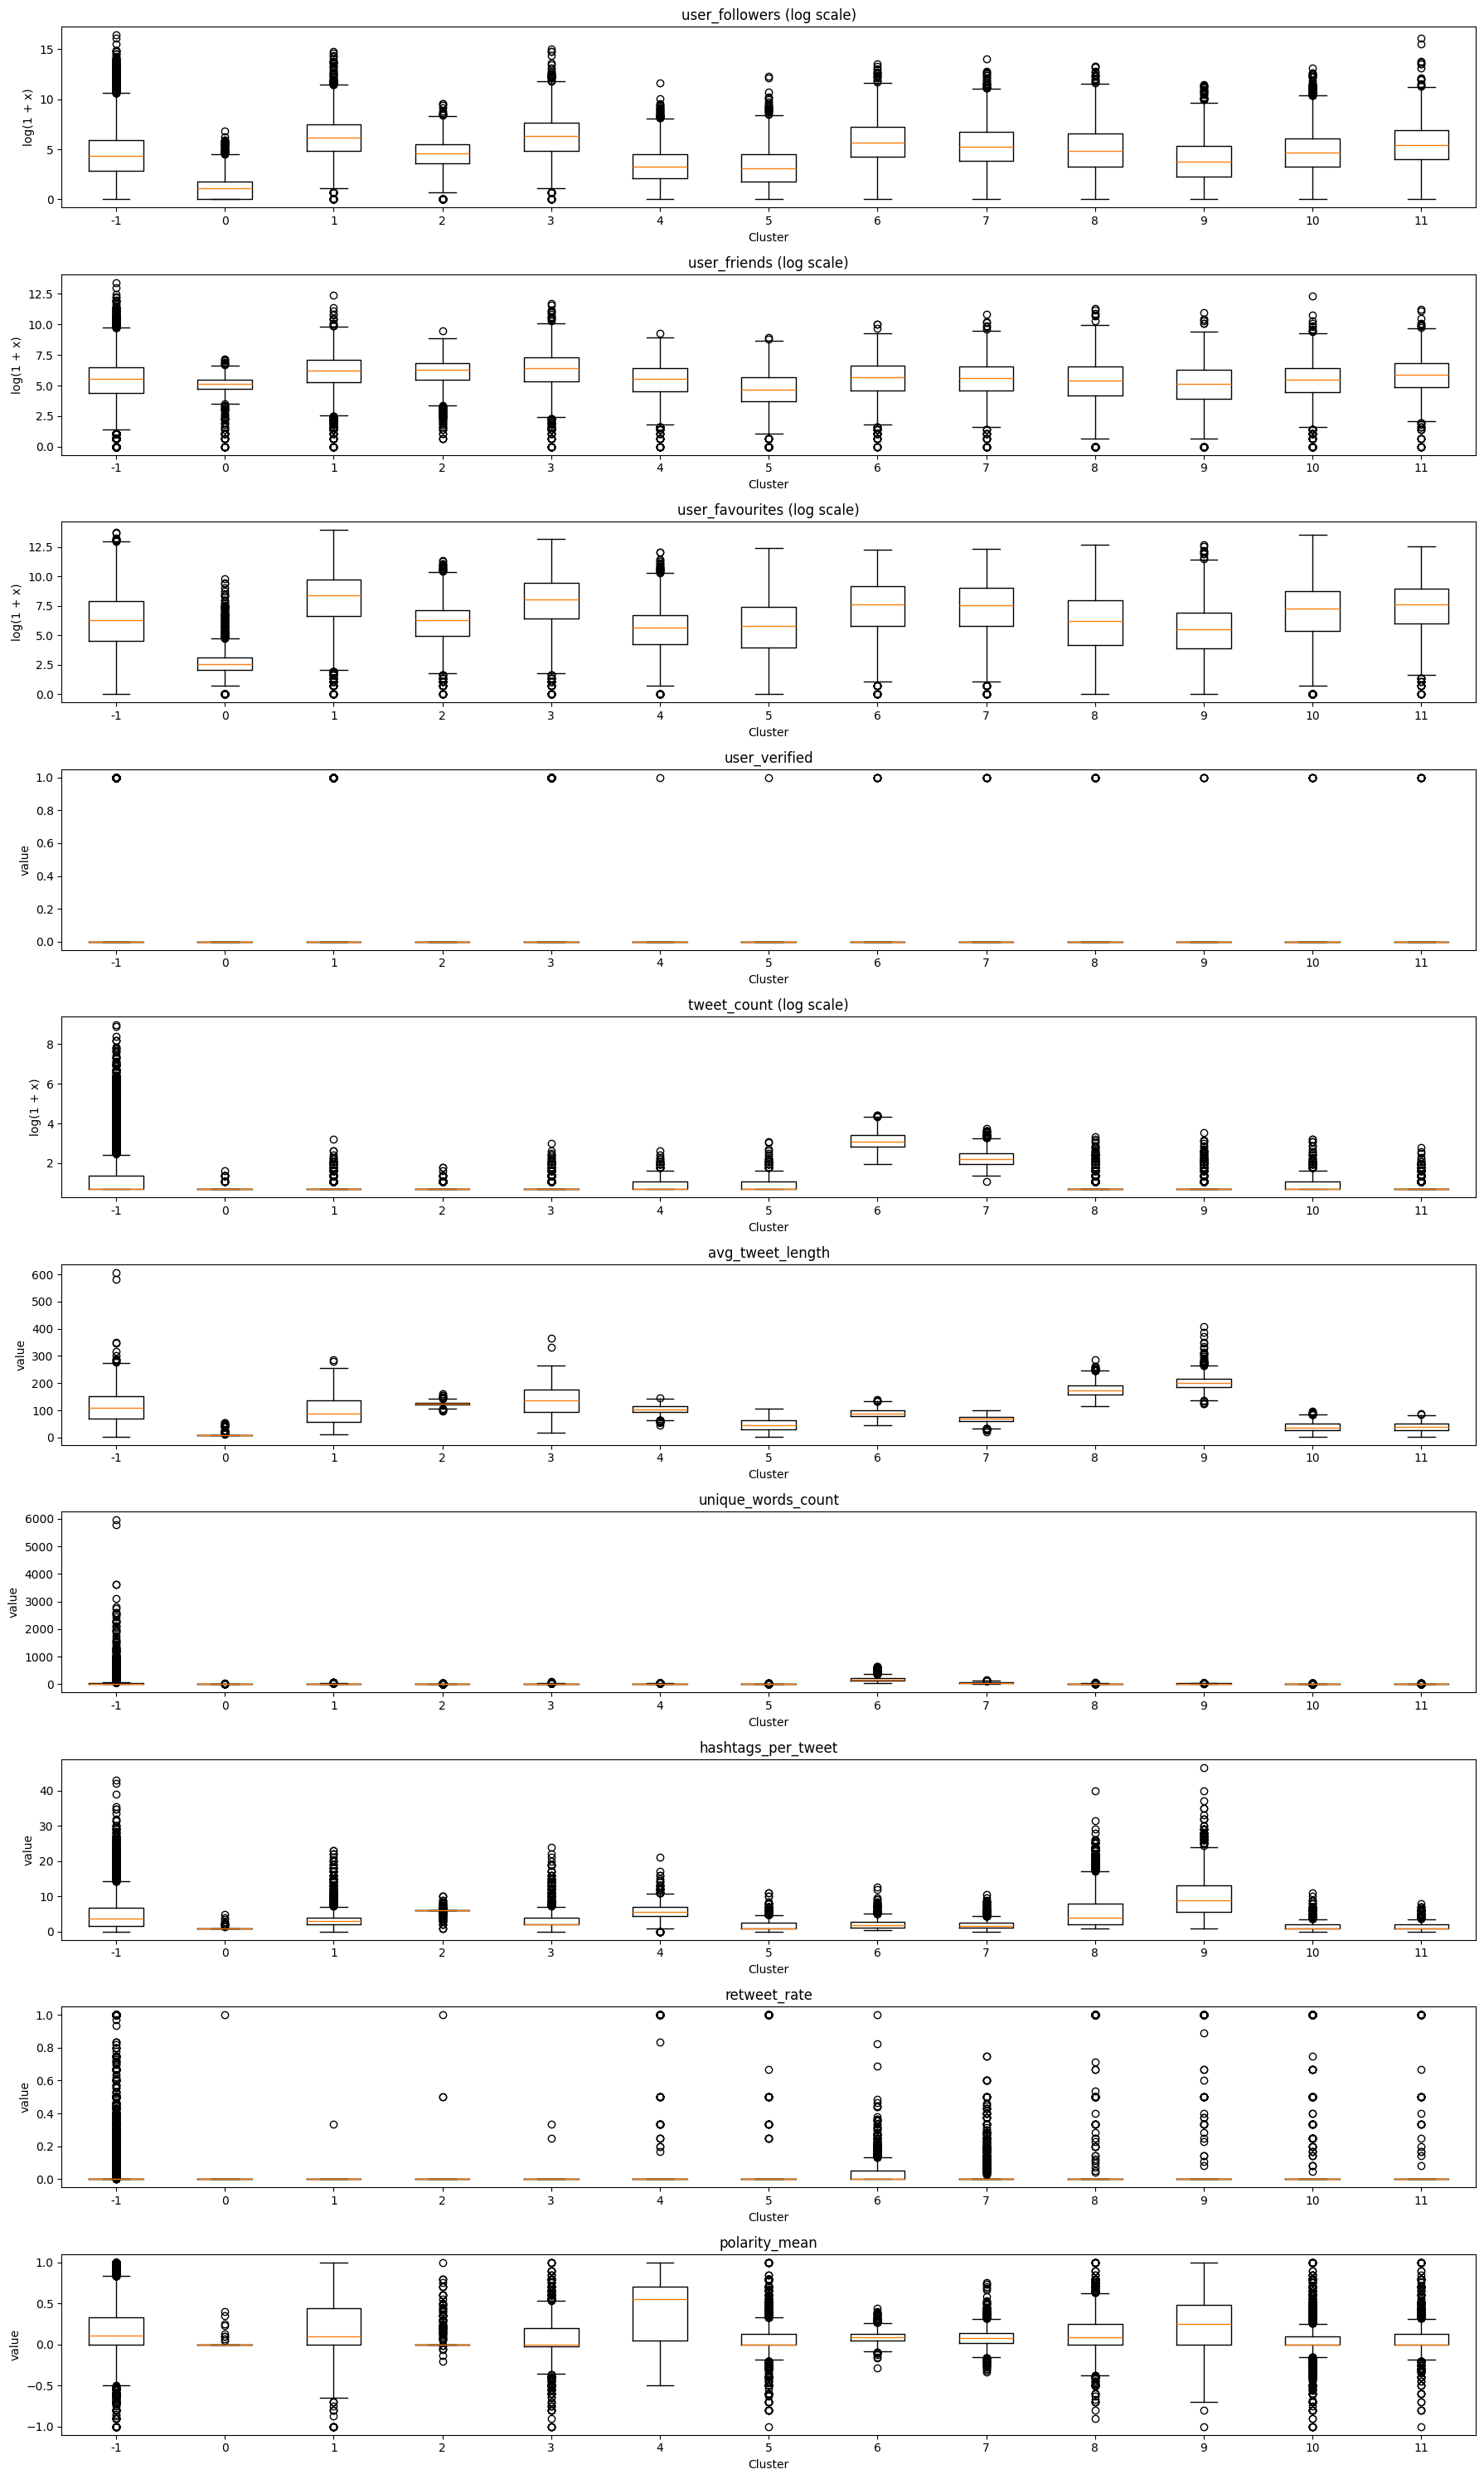

In [22]:
n_rows = len(features)
fig, axes = plt.subplots(n_rows, 1, figsize=(18, 3 * n_rows), sharex=False)

if n_rows == 1:
    axes = [axes]

for i, feature in enumerate(features):
    ax = axes[i]

    # Daten für alle Cluster sammeln
    data_per_cluster = []
    clusters = sorted(df_cluster_evaluation['cluster'].unique())

    for c in clusters:
        values = df_cluster_evaluation.loc[df_cluster_evaluation['cluster'] == c, feature].dropna()
        # log-transform wenn Feature in log_features
        if feature in log_features:
            values = np.log1p(values.astype(float))  # log(1 + x), verhindert Probleme bei 0

        data_per_cluster.append(values)

    # Boxplot zeichnen
    ax.boxplot(data_per_cluster, labels=clusters)

    # Titel
    if feature in log_features:
        ax.set_title(f"{feature} (log scale)")
        ax.set_ylabel("log(1 + x)")
    else:
        ax.set_title(feature)
        ax.set_ylabel("value")

    ax.set_xlabel("Cluster")

plt.tight_layout()
plt.show()

In [ ]:
cols_to_add = [
    'tweet_count', 'avg_tweet_length', 'unique_words_count',
    'hashtags_per_tweet', 'retweet_rate', 'polarity_mean',
    'sentiment_distribution', 'top_hashtags'
]

df_merged = df.merge(
    df_cluster_evaluation[['user_name'] + cols_to_add],
    on='user_name',
    how='left'

)

In [25]:
df_merged.columns

Index(['Unnamed: 0', 'user_name', 'user_location', 'user_description',
       'user_created', 'user_followers', 'user_friends', 'user_favourites',
       'user_verified', 'date', 'text', 'hashtags', 'source', 'is_retweet',
       'cleanText', 'Polarity Score', 'sentiment', 'combined_text',
       'embedding', 'cluster', 'tweet_count', 'avg_tweet_length',
       'unique_words_count', 'hashtags_per_tweet', 'retweet_rate',
       'polarity_mean', 'sentiment_distribution', 'top_hashtags'],
      dtype='object')

In [28]:
df_merged.to_csv("allinfo.csv", index=False, encoding="latin1")

In [34]:
def str_to_array(s):
    # Entfernt [ ] und Zeilenumbrüche
    s = s.strip("[]").replace("\n", " ")
    # String zu Float-Array
    return np.fromstring(s, sep=" ")

# Anwenden auf den DataFrame
df_merged["embedding"] = df_merged["embedding"].apply(str_to_array)

In [26]:
def cluster_centroid(embeddings):
    return np.median(np.stack(embeddings), axis=0)

In [ ]:
from numpy.linalg import norm

def representative_users(df, cluster_id, n_users=5):
    df_tmp = df[df.cluster == cluster_id]

    # Zentrum berechnen
    centroid = cluster_centroid(df_tmp.embedding)

    # Distanz pro Tweet
    df_tmp["dist_to_center"] = df_tmp.embedding.apply(lambda x: norm(x - centroid))

    # Durchschnittliche Distanz pro Nutzer
    user_dist = (df_tmp.groupby("user_name")["dist_to_center"].mean().sort_values().head(n_users))

    return user_dist.index.tolist()

In [37]:
def sample_tweets_per_user(df, users, n_posts=5, random_state=42):
    """
    df       : dein DataFrame mit Tweets
    users    : Liste der ausgewählten Nutzer
    n_posts  : maximale Anzahl zufälliger Tweets pro Nutzer
    """
    sampled = {}
    
    for user in users:
        user_tweets = df[df.user_name == user]
        # falls Nutzer weniger als n_posts hat, wird alles genommen
        sampled[user] = user_tweets.sample(
            n=min(n_posts, len(user_tweets)), 
            random_state=random_state
        )
    
    return sampled


In [41]:
columns_of_interest = [
    "user_name",
    "user_location",
    "user_description",
    "user_followers",
    "user_friends",
    "user_verified",
    "cleanText",
    "hashtags",
    "Polarity Score",
    "sentiment",
    "tweet_count",
    "avg_tweet_length",
    "unique_words_count",
    "hashtags_per_tweet",
    "retweet_rate",
    "polarity_mean",
    "sentiment_distribution",
    "top_hashtags"
]

In [ ]:
pd.set_option("display.max_colwidth", None)

In [54]:
cluster01= representative_users(df_merged, -1)

print(cluster01)

C:\Users\johan\AppData\Local\Temp\ipykernel_1468\859170438.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_tmp["dist_to_center"] = df_tmp.embedding.apply(


['Lai Ngoc Ninh', 'Poston Devan', 'cryptotips', 'rizqi habibbullah', 'Andy Tovey']


In [55]:
sampled_tweets = sample_tweets_per_user(df_merged, cluster01, n_posts=5)
filtered_sampled = {
    user: df_posts[columns_of_interest]
    for user, df_posts in sampled_tweets.items()
}
df_cluster01 = pd.concat(filtered_sampled.values(), ignore_index=True)

df_cluster01

,user_name,user_location,user_description,user_followers,user_friends,user_verified,cleanText,hashtags,Polarity Score,sentiment,tweet_count,avg_tweet_length,unique_words_count,hashtags_per_tweet,retweet_rate,polarity_mean,sentiment_distribution,top_hashtags
0,Lai Ngoc Ninh,NaN,#Followback #ICO #Cryptocurrency #BSC #BNB #HT #BTC #Ethereum,111.0,238.0,False,nervesner great projet strong fundamentals doremon mdpialkhan storiesoflifea matha wetr xaafeeabafddae giveaway binance blockchain btc eth cryptocurency airdrop defi gamefi nfts,"['giveaway', 'Binance', 'Blockchain', 'BTC', 'ETH', 'Cryptocurency', 'Airdrop', 'DeFi', 'GameFi', 'NFTs']",0.616667,1.0,1,177.000000,21,10.000000,0.0,0.616667,{1.0: 1},"[['giveaway',, 'Binance',, 'Blockchain',, 'BTC',, 'ETH',, 'Cryptocurency',, 'Airdrop',, 'DeFi',, 'GameFi',, 'NFTs']]"
1,Poston Devan,Singapore,"#Poker player, Back-end #developer. Proud to be.\n#cryptocurrency #trader\n#bsc #btc #bnb #eth #blockchain\n#followforfollowback",27.0,214.0,False,projectlarix new project solana follow trend ecosystem price pump definitely coming harrykano bkdao airdrop airdrops airdropinspector larix larix solana spl sollet crypto bitcoin,"['Airdrop', 'Airdrops', 'Airdropinspector', 'Larix', 'LARIX', 'Solana', 'SPL', 'Sollet', 'Crypto', 'Bitcoin']",0.068182,1.0,1,178.000000,21,10.000000,0.0,0.068182,{1.0: 1},"[['Airdrop',, 'Airdrops',, 'Airdropinspector',, 'Larix',, 'LARIX',, 'Solana',, 'SPL',, 'Sollet',, 'Crypto',, 'Bitcoin']]"
2,cryptotips,blockchain,"CryptoTrader & Crypto Investor sharing #cryptocurrency news, tips and analysis. Happily working on the blockchain. #BTC #ETH #LINK #UBT ððð°",1412.0,1146,False,bitcoin geopolitical maneuvers,['Bitcoin'],0.000000,0.0,5,33.200000,17,1.000000,0.0,0.000000,{0.0: 5},[['Bitcoin']]
3,cryptotips,blockchain,"CryptoTrader & Crypto Investor sharing #cryptocurrency news, tips and analysis. Happily working on the blockchain. #BTC #ETH #LINK #UBT ððð°",1412.0,1154.0,False,bitcoin threat central bank sovereignty,['Bitcoin'],0.000000,0.0,5,33.200000,17,1.000000,0.0,0.000000,{0.0: 5},[['Bitcoin']]
4,cryptotips,blockchain,"CryptoTrader & Crypto Investor sharing #cryptocurrency news, tips and analysis. Happily working on the blockchain. #BTC #ETH #LINK #UBT ððð°",1412.0,1146.0,False,thank individual independent bitcoin miners china,['Bitcoin'],0.000000,0.0,5,33.200000,17,1.000000,0.0,0.000000,{0.0: 5},[['Bitcoin']]
5,cryptotips,blockchain,"CryptoTrader & Crypto Investor sharing #cryptocurrency news, tips and analysis. Happily working on the blockchain. #BTC #ETH #LINK #UBT ððð°",1412.0,1146,False,brazil launches bitcoin etf,['Bitcoin'],0.000000,0.0,5,33.200000,17,1.000000,0.0,0.000000,{0.0: 5},[['Bitcoin']]
6,cryptotips,blockchain,"CryptoTrader & Crypto Investor sharing #cryptocurrency news, tips and analysis. Happily working on the blockchain. #BTC #ETH #LINK #UBT ððð°",1412.0,1146.0,False,bitcoin narrative war,['Bitcoin'],0.000000,0.0,5,33.200000,17,1.000000,0.0,0.000000,{0.0: 5},[['Bitcoin']]
7,rizqi habibbullah,NaN,"Astrophotography, Crypto Trader #BNB #BTC #TKO",1.0,26.0,False,crustnetwork okex krakenfx mathwallet hotbit_news good job good project adiy missugarika roissaputri_ criptocurrency bnb bitcoin coinmarketcap,"['criptocurrency', 'bnb', 'bitcoin', 'CoinMarketCap']",0.700000,1.0,1,142.000000,15,4.000000,0.0,0.700000,{1.0: 1},"[['criptocurrency',, 'bnb',, 'bitcoin',, 'CoinMarketCap']]"
8,Andy Tovey,NaN,"#Btc cryptocurrency investor Defi Projects providing blockchain news, analysis",94.0,577.0,False,pancakeswap splinterlands gamejet platform play win feel play fill pockets jet tokens nothing much register join referral campaign today day register telegram jettoken tron trx btc doge,"['GameJet', 'jettoken', 'TRON', 'Trx', 'BTC', 'Doge']",0.500000,1.0,11,203.090909,68,5.909091,0.0,0.500000,{1.0: 11},"[['GameJet',, 'jettoken',, 'TRON',, 'BTC',, 'Trx',, 'Doge'], 'doge'], 'TRX',, 'dogearmy']]"
9,Andy Tovey,NaN,"#Btc cryptocurrency inv

In [59]:
cluster0= representative_users(df_merged, 0, 20)

print(cluster0)

[' NBA ', 'socheat suy', 'shouda katuhiro', 'seven å\x93²', 'seewoo vandanee', 'scoobyfan', 'sba_kadiro', 'sayo', 'sayf de sidi sliman', 'satoshi', 'samtolentino', 'salim mc', 'somah', 'salim begar', 'ryouaoi', 'ryo', 'rumina', 'ronald', 'romherman', 'robin boulic']


C:\Users\johan\AppData\Local\Temp\ipykernel_1468\859170438.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_tmp["dist_to_center"] = df_tmp.embedding.apply(


In [60]:
sampled_tweets = sample_tweets_per_user(df_merged, cluster0, n_posts=5)
filtered_sampled = {
    user: df_posts[columns_of_interest]
    for user, df_posts in sampled_tweets.items()
}
df_cluster0 = pd.concat(filtered_sampled.values(), ignore_index=True)

df_cluster0

,user_name,user_location,user_description,user_followers,user_friends,user_verified,cleanText,hashtags,Polarity Score,sentiment,tweet_count,avg_tweet_length,unique_words_count,hashtags_per_tweet,retweet_rate,polarity_mean,sentiment_distribution,top_hashtags
0,NBA,NaN,NaN,1.0,288,False,btc moon,['btc'],0.0,0.0,1,8.0,2,1.0,0.0,0.0,{0.0: 1},[['btc']]
1,socheat suy,NaN,NaN,1.0,307,False,btc moon,['btc'],0.0,0.0,1,8.0,2,1.0,0.0,0.0,{0.0: 1},[['btc']]
2,shouda katuhiro,NaN,NaN,4.0,176,False,btc moon,['btc'],0.0,0.0,1,8.0,2,1.0,0.0,0.0,{0.0: 1},[['btc']]
3,seven å²,NaN,NaN,2.0,133,False,btc moon,['btc'],0.0,0.0,1,8.0,2,1.0,0.0,0.0,{0.0: 1},[['btc']]
4,seewoo vandanee,NaN,NaN,9.0,236,False,btc moon,['btc'],0.0,0.0,1,8.0,2,1.0,0.0,0.0,{0.0: 1},[['btc']]
5,scoobyfan,"Puyallup, WA",NaN,11.0,234,False,btc moon,['btc'],0.0,0.0,1,8.0,2,1.0,0.0,0.0,{0.0: 1},[['btc']]
6,sba_kadiro,NaN,NaN,0.0,130,False,btc moon,['btc'],0.0,0.0,1,8.0,2,1.0,0.0,0.0,{0.0: 1},[['btc']]
7,sayo,NaN,NaN,7.0,103,False,btc moon,['btc'],0.0,0.0,1,8.0,2,1.0,0.0,0.0,{0.0: 1},[['btc']]
8,sayf de sidi sliman,NaN,NaN,2.0,164,False,btc moon,['btc'],0.0,0.0,1,8.0,2,1.0,0.0,0.0,{0.0: 1},[['btc']]
9,satoshi,NaN,NaN,0.0,0,False,btc moon,['btc'],0.0,0.0,1,8.0,2,1.0,0.0,0.0,{0.0: 1},[['btc']]


In [52]:
cluster1= representative_users(df_merged, 1)

print(cluster1)

['Daniel Simao', 'Johnny Bell', 'Sam Price', 'Rohan Puri', 'Asjad Ahmed']


C:\Users\johan\AppData\Local\Temp\ipykernel_1468\859170438.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_tmp["dist_to_center"] = df_tmp.embedding.apply(


In [53]:
sampled_tweets = sample_tweets_per_user(df_merged, cluster1, n_posts=5)
filtered_sampled = {
    user: df_posts[columns_of_interest]
    for user, df_posts in sampled_tweets.items()
}
df_cluster1 = pd.concat(filtered_sampled.values(), ignore_index=True)

df_cluster1

,user_name,user_location,user_description,user_followers,user_friends,user_verified,cleanText,hashtags,Polarity Score,sentiment,tweet_count,avg_tweet_length,unique_words_count,hashtags_per_tweet,retweet_rate,polarity_mean,sentiment_distribution,top_hashtags
0,Daniel Simao,NaN,"Founder @Digitaltechshow - Techie & Customer Experience Manager - Sport, Music, Languages (English, Spanish, French, Portuguese)",790.0,1666.0,False,today begins olympics tokyo olympics let enjoy olympics olympicgames tokyo tokyoolympics,"['Olympics', 'OlympicGames', 'Tokyo2020', 'TokyoOlympics']",0.400000,1.0,1,88.0,8,4.0,0.0,0.400000,{1.0: 1},"[['Olympics',, 'OlympicGames',, 'Tokyo2020',, 'TokyoOlympics']]"
1,Johnny Bell,North/Central Florida (#NCF),Christian. Husband. Stepdaddy. Author of #TaketheShot and #TheDirtCourt. Educator. Ed.D Student. #BasketballJunkie. Fan of #CHH. #DIYer. ðð½ððð¨ð½âð«ððð§ð,342.0,864.0,False,beautiful openingceremony far tokyoolympics hope fun safe experience athletes coaches support staff others imagine accomplish wrk together teamwork oneteam olympics,"['openingceremony', 'tokyo2020olympics', 'teamwork', 'oneteam', 'olympics']",0.437500,1.0,1,164.0,20,5.0,0.0,0.437500,{1.0: 1},"[['openingceremony',, 'tokyo2020olympics',, 'teamwork',, 'oneteam',, 'olympics']]"
2,Sam Price,"Tokyo, Japan","Sports Editor @touchline_com. Currently in Tokyo covering the Olympics.\nPreviously @RacingPost, @unibirmingham grad and keen runner.",582.0,1010.0,False,arrived tokyo feeling privileged attend light spectator ban trying best tell stories athletes worked hard exceptionally challenging circumstances make tokyo olympics olympicgames strongertogether,"['tokyo2020', 'olympics', 'olympicgames', 'strongertogether']",0.402083,1.0,1,195.0,22,4.0,0.0,0.402083,{1.0: 1},"[['tokyo2020',, 'olympics',, 'olympicgames',, 'strongertogether']]"
3,Rohan Puri,NaN,"MSc Sport Management graduate, University of Stirling. \nFormer Journalist with Scroll Media.\nFormer Sports Journalist with The Times of India.",90.0,223.0,False,first day first byline tokyoolympics tokyo olympics olympics olympicgames olympicgamestokyo,"['TokyoOlympics', 'Tokyo2021', 'Olympics', 'Olympics2021', 'OlympicGames', 'OLYMPICGAMESTOKYO2020']",0.250000,1.0,1,91.0,8,6.0,0.0,0.250000,{1.0: 1},"[['TokyoOlympics',, 'Tokyo2021',, 'Olympics',, 'Olympics2021',, 'OlympicGames',, 'OLYMPICGAMESTOKYO2020']]"
4,Asjad Ahmed,NaN,"Entertainment Tracker\n | Graphic Designer | Web-designer | Video Editor | YouTuber | \n\nOfficial news, Tweets\n\n@AhmdAsjad",221.0,455.0,False,olympics olympic cauldron lit naomiosaka honours curtain rises tokyo openingceremony strongertogether olympic olympics openingceremony olympic erttokyo olympicgames ãªãªã³ããã¯,"['Tokyo2020', 'OpeningCeremony', 'StrongerTogether', 'Olympic', 'Olympics', 'OpeningCeremony', 'æ±äº¬2020', 'ERTTokyo2020', 'OlympicGames', 'ãªãªã³ããã¯']",0.000000,0.0,2,196.0,20,13.0,0.0,0.000000,{0.0: 2},"['OpeningCeremony',, 'Olympic',, 'StrongerTogether',, 'ERTTokyo2020',, 'OlympicGames',, ['Olympics',, 'Tokyo2020',, 'Olympics2020',, 'ãªãªã³ããã¯',, 'UnitedByEmotion',]"
5,Asjad Ahmed,NaN,"Entertainment Tracker\n | Graphic Designer | Web-designer | Video Editor | YouTuber | \n\nOfficial news, Tweets\n\n@AhmdAsjad",221.0,455.0,False,olympics olympics openingceremony olympic tokyo olympic strongertogether olympic athletes erttokyo olympics ãªãªã³ããã¯ olympicgames unitedbyemotion strongertogether colombo srilanka japan tokyoolympics,"['Olympics', 'OpeningCeremony', 'Tokyo2020', 'Olympic', 'StrongerTogether', 'Olympic', 'ERTTokyo2020', 'Olympics2020', 'ãªãªã³ããã¯', 'OlympicGames', 'UnitedByEmotion', 'StrongerTogether', 'Colombo', 'srilanka', 'Japan', 'TokyoOlympics']",0.000000,0.0,2,196.0,20,13.0,0.0,0.000000,{0.0: 2},"['OpeningCeremony',, 'Olympic',, 'StrongerTogether',, 'ERTTokyo2020',, 'OlympicGames',, ['Olympics',, 'Tokyo2020',, 'Olympics2020',, 'ãªãªã³ããã¯',, 'UnitedByEmotion',]"


In [63]:
cluster2= representative_users(df_merged, 2, 20)

print(cluster2)

['Bike Roy', 'Alpin', 'Pay', 'rusdi', 'Tims.', 'Nopia Jani', 'Pangestu', 'Yugi', 'Baizid hasan', 'Meggan', 'TÃ¢n Vlog', 'GindaHrp', 'SARA', 'Aqib Nawaz khan', 'Khoirul', 'GonGon', 'ROPAI', 'Awaz Wahaia,', 'Aomine', 'rimon']


C:\Users\johan\AppData\Local\Temp\ipykernel_1468\859170438.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_tmp["dist_to_center"] = df_tmp.embedding.apply(


In [64]:
sampled_tweets = sample_tweets_per_user(df_merged, cluster2, n_posts=5)
filtered_sampled = {
    user: df_posts[columns_of_interest]
    for user, df_posts in sampled_tweets.items()
}
df_cluster2 = pd.concat(filtered_sampled.values(), ignore_index=True)

df_cluster2

,user_name,user_location,user_description,user_followers,user_friends,user_verified,cleanText,hashtags,Polarity Score,sentiment,tweet_count,avg_tweet_length,unique_words_count,hashtags_per_tweet,retweet_rate,polarity_mean,sentiment_distribution,top_hashtags
0,Bike Roy,NaN,Sjjgfjd,0.0,5.0,False,airdrop xom plusar airdrop pool valued xom referral stakes stakes invite distribution date aug join bsc airdrops binancechain btc,"['Airdrop', 'Airdrop', 'BSC', 'Airdrops', 'BinanceChain', 'BTC']",0.0,0.0,1,129.0,16,6.0,0.0,0.0,{0.0: 1},"[['Airdrop',, 'Airdrop',, 'BSC',, 'Airdrops',, 'BinanceChain',, 'BTC']]"
1,Alpin,NaN,Ndiyh,11.0,25.0,False,airdrop xom plusar airdrop pool valued xom referral stakes stakes invite distribution date aug join bsc airdrops binancechain btc,"['Airdrop', 'Airdrop', 'BSC', 'Airdrops', 'BinanceChain', 'BTC']",0.0,0.0,1,129.0,16,6.0,0.0,0.0,{0.0: 1},"[['Airdrop',, 'Airdrop',, 'BSC',, 'Airdrops',, 'BinanceChain',, 'BTC']]"
2,Pay,NaN,Realistis,44.0,88.0,False,airdrop xom plusar airdrop pool valued xom referral stakes stakes invite distribution date aug join bsc airdrops binancechain btc,"['Airdrop', 'Airdrop', 'BSC', 'Airdrops', 'BinanceChain', 'BTC']",0.0,0.0,1,129.0,16,6.0,0.0,0.0,{0.0: 1},"[['Airdrop',, 'Airdrop',, 'BSC',, 'Airdrops',, 'BinanceChain',, 'BTC']]"
3,rusdi,NaN,hore,0.0,10.0,False,airdrop xom plusar airdrop pool valued xom referral stakes stakes invite distribution date aug join bsc airdrops binancechain btc,"['Airdrop', 'Airdrop', 'BSC', 'Airdrops', 'BinanceChain', 'BTC']",0.0,0.0,1,129.0,16,6.0,0.0,0.0,{0.0: 1},"[['Airdrop',, 'Airdrop',, 'BSC',, 'Airdrops',, 'BinanceChain',, 'BTC']]"
4,Tims.,Kudus,Hehe,1173.0,772.0,False,airdrop xom plusar airdrop pool valued xom referral stakes stakes invite distribution date aug join bsc airdrops binancechain btc,"['Airdrop', 'Airdrop', 'BSC', 'Airdrops', 'BinanceChain', 'BTC']",0.0,0.0,1,129.0,16,6.0,0.0,0.0,{0.0: 1},"[['Airdrop',, 'Airdrop',, 'BSC',, 'Airdrops',, 'BinanceChain',, 'BTC']]"
5,Nopia Jani,NaN,Hallo,134.0,86.0,False,airdrop xom plusar airdrop pool valued xom referral stakes stakes invite distribution date aug join bsc airdrops binancechain btc,"['Airdrop', 'Airdrop', 'BSC', 'Airdrops', 'BinanceChain', 'BTC']",0.0,0.0,1,129.0,16,6.0,0.0,0.0,{0.0: 1},"[['Airdrop',, 'Airdrop',, 'BSC',, 'Airdrops',, 'BinanceChain',, 'BTC']]"
6,Pangestu,ID +62,follback ya,71.0,733.0,False,airdrop xom plusar airdrop pool valued xom referral stakes stakes invite distribution date aug join bsc airdrops binancechain btc,"['Airdrop', 'Airdrop', 'BSC', 'Airdrops', 'BinanceChain', 'BTC']",0.0,0.0,1,129.0,16,6.0,0.0,0.0,{0.0: 1},"[['Airdrop',, 'Airdrop',, 'BSC',, 'Airdrops',, 'BinanceChain',, 'BTC']]"
7,Yugi,NaN,ð¶,64.0,455.0,False,airdrop xom plusar airdrop pool valued xom referral stakes stakes invite distribution date aug join bsc airdrops binancechain btc,"['Airdrop', 'Airdrop', 'BSC', 'Airdrops', 'BinanceChain', 'BTC']",0.0,0.0,1,129.0,16,6.0,0.0,0.0,{0.0: 1},"[['Airdrop',, 'Airdrop',, 'BSC',, 'Airdrops',, 'BinanceChain',, 'BTC']]"
8,Baizid hasan,NaN,Go Go Go ð¥,0.0,26.0,False,airdrop xom plusar airdrop pool valued xom referral stakes stakes invite distribution date aug join bsc airdrops binancechain btc,"['Airdrop', 'Airdrop', 'BSC', 'Airdrops', 'BinanceChain', 'BTC']",0.0,0.0,1,129.0,16,6.0,0.0,0.0,{0.0: 1},"[['Airdrop',, 'Airdrop',, 'BSC',, 'Airdrops',, 'BinanceChain',, 'BTC']]"
9,Meggan,NaN,HYJA,38.0,55.0,False,airdrop xom plusar airdrop pool valued xom referral stakes stakes invite distribution date aug join bsc airdrops binancechain btc,"['Airdrop', 'Airdrop', 'BSC', 'Airdrops', 'BinanceChain', 'BTC']",0.0,0.0,1,129.0,16,6.0,0.0,0.0,{0.0: 1},"[['Airdrop',, 'Airdrop',, 'BSC',, 'Airdrops',, 'BinanceChain',, 'BTC']]"


In [65]:
cluster3= representative_users(df_merged, 3)

print(cluster3)

['simon hopkins', 'Feven@á\x8d\x8cá\x89¡â\x9d¤â\x9d¤â\x9d¤', 'medhin', 'Patricia dos Santos Paton ð\x9f\x8f´ó\xa0\x81§ó\xa0\x81¢ó\xa0\x81³ó\xa0\x81£ó\xa0\x81´ó\xa0\x81¿ð\x9f\x87§ð\x9f\x87·', 'Jayde Bradley']


C:\Users\johan\AppData\Local\Temp\ipykernel_1468\859170438.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_tmp["dist_to_center"] = df_tmp.embedding.apply(


In [66]:
sampled_tweets = sample_tweets_per_user(df_merged, cluster3, n_posts=5)
filtered_sampled = {
    user: df_posts[columns_of_interest]
    for user, df_posts in sampled_tweets.items()
}
df_cluster3 = pd.concat(filtered_sampled.values(), ignore_index=True)

df_cluster3

,user_name,user_location,user_description,user_followers,user_friends,user_verified,cleanText,hashtags,Polarity Score,sentiment,tweet_count,avg_tweet_length,unique_words_count,hashtags_per_tweet,retweet_rate,polarity_mean,sentiment_distribution,top_hashtags
0,simon hopkins,Singapore,Backed Oxford vaccine & UKâs first antibody test. Provider of Specialist Long-Term Care. Investor in ground breaking healthcare. Opposed to lockdowns,39.0,167.0,False,julanijulani nick_the_geek davidedionisi kids told clubbing unless double vaccinated extreme coercion country youth illegal notocoercion abuseofpower covidpropaganda covidvaccine,"['notocoercion', 'AbuseOfPower', 'covidpropaganda', 'CovidVaccine']",-0.208333,0.0,1,178.0,18,4.0,0.0,-0.208333,{0.0: 1},"[['notocoercion',, 'AbuseOfPower',, 'covidpropaganda',, 'CovidVaccine']]"
1,Feven@áá¡â¤â¤â¤,Toronto,Researcher and Advisor,59.0,267.0,False,rest world distributing covidvaccine childrenoftigray starving millions almost medical care save common illnesses usun unhumanrights nato haavisto josepborrellf eu_commission secblinken wfp,"['CovidVaccine', 'ChildrenOfTigray']",-0.150000,0.0,1,189.0,21,2.0,0.0,-0.150000,{0.0: 1},"[['CovidVaccine',, 'ChildrenOfTigray']]"
2,medhin,NaN,ð stop TigrayGenocide â¤ï¸ð,1208.0,1201.0,False,rest world distributing covidvaccine childrenoftigray starving millions almost medical care save common illnesses usun unhumanrights nato haavisto josepborrellf eu_commission secblinken wfp,"['CovidVaccine', 'ChildrenOfTigray']",-0.150000,0.0,1,189.0,21,2.0,0.0,-0.150000,{0.0: 1},"[['CovidVaccine',, 'ChildrenOfTigray']]"
3,Patricia dos Santos Paton ð´ó §ó ¢ó ³ó £ó ´ó ¿ð§ð·,East Ren Scotland,"Scientist, Ph.D. Immunology | tutor | mother | Tweets personal",95.0,206.0,False,ironic years old daughter might end getting covidvaccine world country constantly slagged starting vaccinate kids return school,['CovidVaccine'],0.075000,1.0,1,127.0,17,1.0,0.0,0.075000,{1.0: 1},[['CovidVaccine']]
4,Jayde Bradley,London,"Supporter Development Co-ordinator at @CAATuk, tweeting in a personal capacity. She/her",558.0,582.0,False,sweaty happy double jabbed moderna essential gov plays role making sure everyone everywhere around world gets covidvaccine vaccineswork vaccineforall,"['moderna', 'CovidVaccine', 'VaccinesWork', 'VaccineForAll']",0.325000,1.0,1,149.0,19,4.0,0.0,0.325000,{1.0: 1},"[['moderna',, 'CovidVaccine',, 'VaccinesWork',, 'VaccineForAll']]"


In [71]:
cluster4= representative_users(df_merged, 4, 20)

print(cluster4)

['sushil kumar', 'Subhash', 'monikaasri753@gmail.com', 'Saiful hidayat', 'Samira', 'azkaf', 'Isfat Ahmed Salam', 'Ari Po', 'Nadeeja Wedisinghe', 'Comfort', 'michoye', 'Subadri', 'Md Rakibul islam bappy', 'Aryanto', 'Kumudra', 'dede nurhasan', 'Ymahmoudi', 'Chudamani Sahu', 'Jashim Mia', 'Moni']


C:\Users\johan\AppData\Local\Temp\ipykernel_1468\859170438.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_tmp["dist_to_center"] = df_tmp.embedding.apply(


In [72]:
sampled_tweets = sample_tweets_per_user(df_merged, cluster4, n_posts=5)
filtered_sampled = {
    user: df_posts[columns_of_interest]
    for user, df_posts in sampled_tweets.items()
}
df_cluster4 = pd.concat(filtered_sampled.values(), ignore_index=True)

df_cluster4

,user_name,user_location,user_description,user_followers,user_friends,user_verified,cleanText,hashtags,Polarity Score,sentiment,tweet_count,avg_tweet_length,unique_words_count,hashtags_per_tweet,retweet_rate,polarity_mean,sentiment_distribution,top_hashtags
0,sushil kumar,"Tohana, India",NaN,6.0,297.0,False,awesome project rinkusinghdesh sunitas ritik airdrop airdrops airdropinspector binancesmartchain bsc elv crypto bitcoin,"['Airdrop', 'Airdrops', 'Airdropinspector', 'BinanceSmartChain', 'BSC', 'ELV', 'Crypto', 'Bitcoin']",1.000000,1.0,1,119.0,13,8.0,0.0,1.000000,{1.0: 1},"[['Airdrop',, 'Airdrops',, 'Airdropinspector',, 'BinanceSmartChain',, 'BSC',, 'ELV',, 'Crypto',, 'Bitcoin']]"
1,Subhash,NaN,NaN,39.0,415.0,False,nice project manish kamlesh trickyboy durgesh airdrop airdrops airdropinspector binancesmartchain bsc fundifinance cra crypto bitcoin,"['Airdrop', 'Airdrops', 'Airdropinspector', 'BinanceSmartChain', 'BSC', 'FundiFinance', 'CRA', 'Crypto', 'Bitcoin']",0.600000,1.0,1,133.0,15,9.0,0.0,0.600000,{1.0: 1},"[['Airdrop',, 'Airdrops',, 'Airdropinspector',, 'BinanceSmartChain',, 'BSC',, 'FundiFinance',, 'CRA',, 'Crypto',, 'Bitcoin']]"
2,monikaasri753@gmail.com,NaN,NaN,6.0,21.0,False,nice projects guys dapang ardians adestinasy airdrop airdrops airdropinspector bsc binancesmartchain heco hecochain crypto bitcoin,"['Airdrop', 'Airdrops', 'Airdropinspector', 'BSC', 'BinanceSmartChain', 'HECO', 'HecoChain', 'Crypto', 'Bitcoin']",0.600000,1.0,1,130.0,15,9.0,0.0,0.600000,{1.0: 1},"[['Airdrop',, 'Airdrops',, 'Airdropinspector',, 'BSC',, 'BinanceSmartChain',, 'HECO',, 'HecoChain',, 'Crypto',, 'Bitcoin']]"
3,Saiful hidayat,NaN,tetaplah hidup walau tak berguna,9.0,122.0,False,xomdpaas lbank_exchange good projects rammeen ramsing renu giveaway airdrop bsc airdrops binancechain btc,"['GIVEAWAY', 'Airdrop', 'BSC', 'Airdrops', 'BinanceChain', 'BTC']",0.700000,1.0,1,105.0,13,6.0,0.0,0.700000,{1.0: 1},"[['GIVEAWAY',, 'Airdrop',, 'BSC',, 'Airdrops',, 'BinanceChain',, 'BTC']]"
4,Samira,NaN,NaN,2.0,295,False,nice project muajj mtthgrade dmpro seehr_ cryptocurrency bsc bitcoin ethereum eth airdrop bounty safethehumanity sth airdropstario,"['cryptocurrency', 'BSC', 'Bitcoin', 'Ethereum', 'ETH', 'Airdrop', 'bounty', 'SafeTheHumanity', 'STH', 'AirdropStario']",0.600000,1.0,1,130.0,16,10.0,0.0,0.600000,{1.0: 1},"[['cryptocurrency',, 'BSC',, 'Bitcoin',, 'Ethereum',, 'ETH',, 'Airdrop',, 'bounty',, 'SafeTheHumanity',, 'STH',, 'AirdropStario']]"
5,azkaf,indonesia,funny world,13.0,71.0,False,nice project debiadi hackimjelly ansukhera airdrop airdrops airdropinspector binancesmartchain bsc fundifinance cra crypto bitcoin,"['Airdrop', 'Airdrops', 'Airdropinspector', 'BinanceSmartChain', 'BSC', 'FundiFinance', 'CRA', 'Crypto', 'Bitcoin']",0.600000,1.0,1,130.0,14,9.0,0.0,0.600000,{1.0: 1},"[['Airdrop',, 'Airdrops',, 'Airdropinspector',, 'BinanceSmartChain',, 'BSC',, 'FundiFinance',, 'CRA',, 'Crypto',, 'Bitcoin']]"
6,Isfat Ahmed Salam,NaN,NaN,19.0,117.0,False,xomdpaas lbank_exchange good project shofiulfarukbd sultana shohelr bsc airdrops binancechain btc,"['BSC', 'Airdrops', 'BinanceChain', 'BTC']",0.700000,1.0,1,97.0,11,4.0,0.0,0.700000,{1.0: 1},"[['BSC',, 'Airdrops',, 'BinanceChain',, 'BTC']]"
7,Ari Po,NaN,NaN,9.0,186.0,False,xomdpaas lbank_exchange nice project parmen tarjo zahra moti katara giveaway airdrop airdrop bsc airdrops binancechain btc,"['GIVEAWAY', 'Airdrop', 'Airdrop', 'BSC', 'Airdrops', 'BinanceChain', 'BTC']",0.600000,1.0,1,122.0,15,7.0,0.0,0.600000,{1.0: 1},"['Airdrop',, ['GIVEAWAY',, 'BSC',, 'Airdrops',, 'BinanceChain',, 'BTC']]"
8,Nadeeja Wedisinghe,NaN,NaN,17.0,180.0,False,pacoca_io good project navindu carlaho sasa airdrop airdrops airdropinspector binancesmartchain bsc pacoca bnb crypto bitcoin,"['Airdrop', 'Airdrops', 'Airdropinspector', 'BinanceSmartChain', 'BSC', 'Pacoca', 'BNB', 'Crypto', 'Bitcoin']",0.700000,1.0,1,125.0,15,9.0,0.0,0.700000,{1.0: 1},"[['Airdrop',, 'Airdrops',, 'Airdropinspector',, 'BinanceSmartChain',, 'BSC',, '

In [73]:
cluster5= representative_users(df_merged, 5, 20)

print(cluster5)

['thisisnotbearish', 'qba', 'mtuncay', 'Miss Hyde', 'E MAN', 'Enes ð\x9f\x87¹ð\x9f\x87·', 'Pouriya Arabloo', 'Svene', 'Shawn Kicielinski', 'Adil Jessa', 'Û±Û¹', '1985 kanishka bombing done by Canadian government', 'primal', 'ï®¼â\x80\x8câ\x80\x8câ\x80\x8cØ¢Ù\x82Ø§â\x80\x8cØ¨Ø²Ø±Ú¯', 'Obi Wan Shakaki', 'Mee Fabulously', 'Nova', 'boynas', 'rikosmashouse', 'Giuseppe Persico']


C:\Users\johan\AppData\Local\Temp\ipykernel_1468\859170438.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_tmp["dist_to_center"] = df_tmp.embedding.apply(


In [74]:
sampled_tweets = sample_tweets_per_user(df_merged, cluster5, n_posts=5)
filtered_sampled = {
    user: df_posts[columns_of_interest]
    for user, df_posts in sampled_tweets.items()
}
df_cluster5 = pd.concat(filtered_sampled.values(), ignore_index=True)

df_cluster5

,user_name,user_location,user_description,user_followers,user_friends,user_verified,cleanText,hashtags,Polarity Score,sentiment,tweet_count,avg_tweet_length,unique_words_count,hashtags_per_tweet,retweet_rate,polarity_mean,sentiment_distribution,top_hashtags
0,thisisnotbearish,NaN,NaN,432.0,142.0,False,btc,['btc'],0.000000,0.0,1,3.0,1,1.0,0.0,0.000000,{0.0: 1},[['btc']]
1,qba,NaN,NaN,621.0,89.0,False,btc,['BTC'],0.000000,0.0,1,3.0,1,1.0,0.0,0.000000,{0.0: 1},[['BTC']]
2,mtuncay,NaN,NaN,3.0,136.0,False,btc,['btc'],0.000000,0.0,1,3.0,1,1.0,0.0,0.000000,{0.0: 1},[['btc']]
3,Miss Hyde,NaN,NaN,66.0,192.0,False,goes come bitcoin cryptocurrency,"['Bitcoin', 'cryptocurrency']",0.000000,0.0,1,32.0,4,2.0,0.0,0.000000,{0.0: 1},"[['Bitcoin',, 'cryptocurrency']]"
4,E MAN,NaN,NaN,1.0,35.0,False,bitcoin well right,['Bitcoin'],0.285714,1.0,1,18.0,3,1.0,0.0,0.285714,{1.0: 1},[['Bitcoin']]
5,Enes ð¹ð·,NaN,NaN,163.0,629.0,False,coming bitcoin,['bitcoin'],0.000000,0.0,1,14.0,2,1.0,0.0,0.000000,{0.0: 1},[['bitcoin']]
6,Pouriya Arabloo,NaN,NaN,0.0,5,False,bitcoin soon trader traderepublic btc cryptocurrency,"['Bitcoin', 'Trader', 'traderepublic', 'BTC', 'cryptocurrency']",0.000000,0.0,1,52.0,6,5.0,0.0,0.000000,{0.0: 1},"[['Bitcoin',, 'Trader',, 'traderepublic',, 'BTC',, 'cryptocurrency']]"
7,Svene,NaN,NaN,3.0,70,False,good news bitcoin,['Bitcoin'],0.700000,1.0,1,17.0,3,1.0,0.0,0.700000,{1.0: 1},[['Bitcoin']]
8,Shawn Kicielinski,"Washington, PA",NaN,15.0,68.0,False,come btc,['BTC'],0.000000,0.0,1,8.0,2,1.0,0.0,0.000000,{0.0: 1},[['BTC']]
9,Adil Jessa,"Greater Vancouver, British Columbia",NaN,169.0,382,False,bitcoin let gooooo btc,"['Bitcoin', 'btc']",0.000000,0.0,1,22.0,4,2.0,0.0,0.000000,{0.0: 1},"[['Bitcoin',, 'btc']]"


In [79]:
cluster6= representative_users(df_merged, 6)

print(cluster6)

['NFTheCryptoð\x9f\x93\x89Sniperð\x9f\x93\x88', 'MajorLeagueCrypto', 'Mr.TyCoONð\x9f\x93\x88ð\x9f\x91\x91', 'crypto proud', 'CryptoGrogu ð\x9f\x90\x88â\x98\xa0ð\x9f\x9f¢ð\x9f\x94´']


C:\Users\johan\AppData\Local\Temp\ipykernel_1468\859170438.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_tmp["dist_to_center"] = df_tmp.embedding.apply(


In [80]:
sampled_tweets = sample_tweets_per_user(df_merged, cluster6, n_posts=5)
filtered_sampled = {
    user: df_posts[columns_of_interest]
    for user, df_posts in sampled_tweets.items()
}
df_cluster6 = pd.concat(filtered_sampled.values(), ignore_index=True)

df_cluster6

,user_name,user_location,user_description,user_followers,user_friends,user_verified,cleanText,hashtags,Polarity Score,sentiment,tweet_count,avg_tweet_length,unique_words_count,hashtags_per_tweet,retweet_rate,polarity_mean,sentiment_distribution,top_hashtags
0,NFTheCryptoðSniperð,Blockchain,"Cryptocurrency Trader + Investor | DM for #moonbag | Tweets are not financial advice #DYOR . NO paid group , Never DM you first . #Bitcoin | #BTC $ETH #BNB",8339.0,1298.0,False,coinbase amp clv know know bitcoin binance cryptocurrency,"['Coinbase', 'Bitcoin', 'Binance', 'cryptocurrency']",0.000000,0.0,32,77.593750,182,3.437500,0.000000,0.077530,"{1.0: 13, 0.0: 19}","['Binance',, 'Bitcoin',, 'cryptocurrency'], ['Bitcoin',, 'cryptocurrencies'], ['Bitcoin'], 'Crypto'], ['GTC',, 'Bitcoin'], 'DeFi',]"
1,NFTheCryptoðSniperð,Blockchain,"Cryptocurrency Trader + Investor | DM for #moonbag | Tweets are not financial advice #DYOR . NO paid group , Never DM you first . #Bitcoin | #BTC $ETH #BNB",8340.0,1298.0,False,good morning bitcoin hope bought dips yesterday btc eth bnb icp gtc shib sol ftt doge shib chz matic enj rvn bitcoin binance crypto,"['Bitcoin', 'Bitcoin', 'Binance', 'Crypto']",0.700000,1.0,32,77.593750,182,3.437500,0.000000,0.077530,"{1.0: 13, 0.0: 19}","['Binance',, 'Bitcoin',, 'cryptocurrency'], ['Bitcoin',, 'cryptocurrencies'], ['Bitcoin'], 'Crypto'], ['GTC',, 'Bitcoin'], 'DeFi',]"
2,NFTheCryptoðSniperð,Blockchain,"Cryptocurrency Trader + Investor | DM for #moonbag | Tweets are not financial advice #DYOR . NO paid group , Never DM you first . #Bitcoin | #BTC $ETH #BNB",8339.0,1298.0,False,doge doge bad far new elon profile picture bitcoin binance cryptocurrency,"['DOGE', 'Elon', 'Bitcoin', 'Binance', 'cryptocurrency']",-0.154545,0.0,32,77.593750,182,3.437500,0.000000,0.077530,"{1.0: 13, 0.0: 19}","['Binance',, 'Bitcoin',, 'cryptocurrency'], ['Bitcoin',, 'cryptocurrencies'], ['Bitcoin'], 'Crypto'], ['GTC',, 'Bitcoin'], 'DeFi',]"
3,NFTheCryptoðSniperð,Blockchain,"Cryptocurrency Trader + Investor | DM for #moonbag | Tweets are not financial advice #DYOR . NO paid group , Never DM you first . #Bitcoin | #BTC $ETH #BNB",8340.0,1298.0,False,cz_binance needless say success bitcoin btc,['Bitcoin'],-0.100000,0.0,32,77.593750,182,3.437500,0.000000,0.077530,"{1.0: 13, 0.0: 19}","['Binance',, 'Bitcoin',, 'cryptocurrency'], ['Bitcoin',, 'cryptocurrencies'], ['Bitcoin'], 'Crypto'], ['GTC',, 'Bitcoin'], 'DeFi',]"
4,NFTheCryptoðSniperð,Blockchain,"Cryptocurrency Trader + Investor | DM for #moonbag | Tweets are not financial advice #DYOR . NO paid group , Never DM you first . #Bitcoin | #BTC $ETH #BNB",8338.0,1298.0,False,keep keep strong support around following vol let see goes nfa bitcoin binance cryptocurrency,"['KEEP', 'Bitcoin', 'Binance', 'cryptocurrency']",0.216667,1.0,32,77.593750,182,3.437500,0.000000,0.077530,"{1.0: 13, 0.0: 19}","['Binance',, 'Bitcoin',, 'cryptocurrency'], ['Bitcoin',, 'cryptocurrencies'], ['Bitcoin'], 'Crypto'], ['GTC',, 'Bitcoin'], 'DeFi',]"
5,MajorLeagueCrypto,The Block,Accredited Crypto Enthusiasts | #btc | Smart Money Educators | Tweets Are Not Financial Advice | #BOTB 2648,398.0,1727.0,False,crypto especially nfts ern bitcoin ada ethereum,"['crypto', 'NFTs', 'ERN', 'Bitcoin', 'ADA', 'Ethereum']",0.000000,0.0,23,69.565217,142,2.608696,0.043478,0.130102,"{1.0: 8, 0.0: 15}","['Bitcoin',, ['Bitcoin'], ['Bitcoin',, 'Ethereum'], 'ADA',, ['bitcoin'], 'Ethereum',, 'NFTs',, ['bitcoin',, 'Bitcoin']]"
6,MajorLeagueCrypto,NaN,Accredited Crypto Enthusiasts | #btc | Smart Money Educators | Tweets Are Not Financial Advice,229.0,1090.0,False,peak yet people think going multi year bull market rookies bitcoin,['Bitcoin'],0.000000,0.0,23,69.565217,142,2.608696,0.043478,0.130102,"{1.0: 8, 0.0: 15}","['Bitcoin',, ['Bitcoin'], ['Bitcoin',, 'Ethereum'], 'ADA',, ['bitcoin'], 'Ethereum',, 'NFTs',, ['bitcoin',, 'Bitcoin']]"
7,MajorLeagueCrypto,NaN,Accredited Crypto Enthusiasts | #btc | Smart Money Educators,16.0,27

In [81]:
cluster7= representative_users(df_merged, 7)

print(cluster7)

['Akash_', 'Pablo', 'Zach Francis', 'The Crypto Blade', 'Bitcoin In My Mind']


C:\Users\johan\AppData\Local\Temp\ipykernel_1468\859170438.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_tmp["dist_to_center"] = df_tmp.embedding.apply(


In [82]:
sampled_tweets = sample_tweets_per_user(df_merged, cluster7, n_posts=5)
filtered_sampled = {
    user: df_posts[columns_of_interest]
    for user, df_posts in sampled_tweets.items()
}
df_cluster7 = pd.concat(filtered_sampled.values(), ignore_index=True)

df_cluster7

,user_name,user_location,user_description,user_followers,user_friends,user_verified,cleanText,hashtags,Polarity Score,sentiment,tweet_count,avg_tweet_length,unique_words_count,hashtags_per_tweet,retweet_rate,polarity_mean,sentiment_distribution,top_hashtags
0,Akash_,NaN,#Bitcoin\nTrading with passion ! \nContent Creator at times !\nMusician all time !\n\n|Optimistic| |Healer| |Vibes| |Hustle|,624.0,271,False,relatable btc bitcoin eth bnb btt win,"['btc', 'Bitcoin', 'eth', 'bnb', 'btt', 'win']",0.800000,1.0,6,61.666667,40,4.500000,0.000000,0.190476,"{1.0: 3, 0.0: 3}","['Bitcoin',, 'btc',, 'bnb',, ['Bitcoin',, ['btc',, 'eth',, 'btt',, 'win'], 'wrx'], ['Alts',]"
1,Akash_,NaN,#Bitcoin\nTrading with passion ! \nContent Creator at times !\nMusician all time !\n\n|Optimistic| |Healer| |Vibes| |Hustle|,624.0,271,False,time retire bed let hope win bitcoin btc bnb wrx,"['Bitcoin', 'btc', 'bnb', 'wrx']",0.800000,1.0,6,61.666667,40,4.500000,0.000000,0.190476,"{1.0: 3, 0.0: 3}","['Bitcoin',, 'btc',, 'bnb',, ['Bitcoin',, ['btc',, 'eth',, 'btt',, 'win'], 'wrx'], ['Alts',]"
2,Akash_,NaN,#Bitcoin\nTrading with passion ! \nContent Creator at times !\nMusician all time !\n\n|Optimistic| |Healer| |Vibes| |Hustle|,623.0,302.0,False,elonmusk made boring fck ath crypto dogeday doge btc bitcoin,"['Crypto', 'DogeDay', 'doge', 'btc', 'Bitcoin']",-1.000000,0.0,6,61.666667,40,4.500000,0.000000,0.190476,"{1.0: 3, 0.0: 3}","['Bitcoin',, 'btc',, 'bnb',, ['Bitcoin',, ['btc',, 'eth',, 'btt',, 'win'], 'wrx'], ['Alts',]"
3,Akash_,NaN,#Bitcoin\nTrading with passion ! \nContent Creator at times !\nMusician all time !\n\n|Optimistic| |Healer| |Vibes| |Hustle|,624.0,271.0,False,people entered crypto days back amp bought alts altcoin bitcoin crypto btc btc eth,"['Alts', 'altcoin', 'Bitcoin', 'Crypto', 'BTC']",0.000000,0.0,6,61.666667,40,4.500000,0.000000,0.190476,"{1.0: 3, 0.0: 3}","['Bitcoin',, 'btc',, 'bnb',, ['Bitcoin',, ['btc',, 'eth',, 'btt',, 'win'], 'wrx'], ['Alts',]"
4,Akash_,NaN,#Bitcoin\nTrading with passion ! \nContent Creator at times !\nMusician all time !\n\n|Optimistic| |Healer| |Vibes| |Hustle|,623.0,302.0,False,sell lows amp bought btc bitcoin xrp ada doge elonmusk jhnnyw aste scottmelker rookiexbt,"['BTC', 'Bitcoin', 'Doge']",0.000000,0.0,6,61.666667,40,4.500000,0.000000,0.190476,"{1.0: 3, 0.0: 3}","['Bitcoin',, 'btc',, 'bnb',, ['Bitcoin',, ['btc',, 'eth',, 'btt',, 'win'], 'wrx'], ['Alts',]"
5,Pablo,Everywhere,#bitcoin #crypto | Trader and investor since 2016 | Retweets are not endorsements | Not financial advice,170.0,189.0,False,bitcoin person following follow follow back altcoiners welcome,['bitcoin'],0.266667,1.0,12,65.916667,90,2.083333,0.000000,0.101429,"{1.0: 4, 0.0: 8}","[['bitcoin'], ['bitcoin',, 'btc'], ['Bitcoin'], ['BinanceTurns4',, 'solana',, 'potato',, 'Airdrops',, 'ADA',, 'Bitcoin',]"
6,Pablo,Everywhere,#bitcoin #crypto | Trader and investor since 2016 | Retweets are not endorsements | Not financial advice,170.0,189.0,False,bitcoin might test lettuce hand mafukrs hitting ath,['Bitcoin'],0.000000,0.0,12,65.916667,90,2.083333,0.000000,0.101429,"{1.0: 4, 0.0: 8}","[['bitcoin'], ['bitcoin',, 'btc'], ['Bitcoin'], ['BinanceTurns4',, 'solana',, 'potato',, 'Airdrops',, 'ADA',, 'Bitcoin',]"
7,Pablo,NaN,NaN,0.0,82.0,False,potatocoinspl specially thanks sir sharing great project hope project future bright success amp moon abhizz ari eoktino ridoo timsukses ddhshsuhejuzjyzzfhorqvjctwfudkuyaeswqiw binanceturns solana potato potato airdrops ada bitcoin memes,"['BinanceTurns4', 'solana', 'potato', 'Airdrops', 'ADA', 'Bitcoin', 'MEMES']",0.400000,1.0,12,65.916667,90,2.083333,0.000000,0.101429,"{1.0: 4, 0.0: 8}","[['bitcoin'], ['bitcoin',, 'btc'], ['Bitcoin'], ['BinanceTurns4',, 'solana',, 'potato',, 'Airdrops',, 'ADA',, 'Bitcoin',]"
8,Pablo,Everywhere,#bitcoin #crypto | Trader and investor since 2016 | Retweets are not endorsements | Not financial advice,170.0,189.0,False,jack garrettmcmanus fill bitcoin maybe,['bitcoin'],0.000000,0.0,12,65.916667,9

In [83]:
cluster8= representative_users(df_merged, 8)

print(cluster8)

['Uncut Globe', 'Alpha Crypto | Signal', 'Randy Stuffer', 'Bitcoin Index', 'Marc Buckner']


C:\Users\johan\AppData\Local\Temp\ipykernel_1468\859170438.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_tmp["dist_to_center"] = df_tmp.embedding.apply(


In [84]:
sampled_tweets = sample_tweets_per_user(df_merged, cluster8, n_posts=5)
filtered_sampled = {
    user: df_posts[columns_of_interest]
    for user, df_posts in sampled_tweets.items()
}
df_cluster8 = pd.concat(filtered_sampled.values(), ignore_index=True)

df_cluster8

,user_name,user_location,user_description,user_followers,user_friends,user_verified,cleanText,hashtags,Polarity Score,sentiment,tweet_count,avg_tweet_length,unique_words_count,hashtags_per_tweet,retweet_rate,polarity_mean,sentiment_distribution,top_hashtags
0,Uncut Globe,United States,"A digital magazine dedicated to empowering investors, businessmen, aspirers for their wholesome growth. \n#World #Money #Business #Tech #BetterLiving #Opinion",110.0,128,False,china new crypto crackdown wipes market crypto bitcoin cryptocurrency blockchain eth ethereum forex money trading bitcoinmining cryptocurrencies bitcoinnews cryptotrading bitcoins investment investing entrepreneur cryptonews invest business,"['crypto', 'bitcoin', 'cryptocurrency', 'blockchain', 'ETH', 'ethereum', 'forex', 'money', 'trading', 'bitcoinmining', 'cryptocurrencies', 'bitcoinnews', 'cryptotrading', 'bitcoins', 'investment', 'investing', 'entrepreneur', 'cryptonews', 'invest', 'business']",0.136364,1.0,1,240.000000,25,20.00,0.0,0.136364,{1.0: 1},"[['crypto',, 'bitcoin',, 'cryptocurrency',, 'blockchain',, 'ETH',, 'ethereum',, 'forex',, 'money',, 'trading',, 'bitcoinmining',]"
1,Alpha Crypto | Signal,NaN,"#BTC #Signal #Bitcoin\nTrading, My Thoughts, News\nMy workð",0.0,9.0,False,bitcoin important invention world history internet crypto bitcoin cryptocurrency blockchain btc ethereum money trading bitcoinmining cryptocurrencies cryptotrading bitcoinnews investment bitcoins investing entrepreneur business eth,"['crypto', 'bitcoin', 'cryptocurrency', 'blockchain', 'btc', 'ethereum', 'money', 'trading', 'bitcoinmining', 'cryptocurrencies', 'cryptotrading', 'bitcoinnews', 'investment', 'bitcoins', 'investing', 'entrepreneur', 'business', 'eth']",0.400000,1.0,3,222.666667,35,18.00,0.0,0.300000,"{1.0: 2, 0.0: 1}","['bitcoin',, 'cryptocurrency',, 'blockchain',, 'btc',, 'ethereum',, 'money',, 'trading',, 'bitcoinmining',, 'cryptocurrencies',, 'cryptotrading',]"
2,Alpha Crypto | Signal,NaN,"#BTC #Signal #Bitcoin\nTrading, My Thoughts, News\nMy workð",0.0,9.0,False,bitcoin banks email postal industry crypto bitcoin cryptocurrency blockchain btc ethereum forex money trading bitcoinmining cryptocurrencies cryptotrading bitcoinnews investment bitcoins investing entrepreneur business,"['crypto', 'bitcoin', 'cryptocurrency', 'blockchain', 'btc', 'ethereum', 'forex', 'money', 'trading', 'bitcoinmining', 'cryptocurrencies', 'cryptotrading', 'bitcoinnews', 'investment', 'bitcoins', 'investing', 'entrepreneur', 'business']",0.000000,0.0,3,222.666667,35,18.00,0.0,0.300000,"{1.0: 2, 0.0: 1}","['bitcoin',, 'cryptocurrency',, 'blockchain',, 'btc',, 'ethereum',, 'money',, 'trading',, 'bitcoinmining',, 'cryptocurrencies',, 'cryptotrading',]"
3,Alpha Crypto | Signal,NaN,"#BTC #Signal #Bitcoin\nTrading, My Thoughts, News\nMy workð",0.0,9.0,False,cocosusdt open trade fibo think best position crypto bitcoin cryptocurrency blockchain btc ethereum forex money trading bitcoinmining cryptocurrencies cryptotrading bitcoinnews investment bitcoins investing entrepreneur,"['COCOSUSDT', 'crypto', 'bitcoin', 'cryptocurrency', 'blockchain', 'btc', 'ethereum', 'forex', 'money', 'trading', 'bitcoinmining', 'cryptocurrencies', 'cryptotrading', 'bitcoinnews', 'investment', 'bitcoins', 'investing', 'entrepreneur']",0.500000,1.0,3,222.666667,35,18.00,0.0,0.300000,"{1.0: 2, 0.0: 1}","['bitcoin',, 'cryptocurrency',, 'blockchain',, 'btc',, 'ethereum',, 'money',, 'trading',, 'bitcoinmining',, 'cryptocurrencies',, 'cryptotrading',]"
4,Randy Stuffer,DM's open for enquiry,#Crypto #forex #bitcoin....previous account @Randyfxm suspended,5.0,20.0,False,first trade week gbpusd forex forextrader bitcoin trading forextrading money forexsignals trader cryptocurrency forexlifestyle investment business entrepreneur investing crypto binaryoptions invest blockchain southafrica usa,"['forex', 'forextrader', 'bitcoin', 'trading', 'forextrading', 'money', 'forexsignals', 'trader', 'cryptocurrency', 'forexlifestyle', 'invest

In [86]:
cluster9= representative_users(df_merged, 9)

print(cluster9)

['Giwing', 'T.A.Mirazð\x9f\x92¸', 'superazer', 'Sultan BTC', 'Obuj Ridoy']


C:\Users\johan\AppData\Local\Temp\ipykernel_1468\859170438.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_tmp["dist_to_center"] = df_tmp.embedding.apply(


In [87]:
sampled_tweets = sample_tweets_per_user(df_merged, cluster9, n_posts=5)
filtered_sampled = {
    user: df_posts[columns_of_interest]
    for user, df_posts in sampled_tweets.items()
}
df_cluster9 = pd.concat(filtered_sampled.values(), ignore_index=True)

df_cluster9

,user_name,user_location,user_description,user_followers,user_friends,user_verified,cleanText,hashtags,Polarity Score,sentiment,tweet_count,avg_tweet_length,unique_words_count,hashtags_per_tweet,retweet_rate,polarity_mean,sentiment_distribution,top_hashtags
0,Giwing,NaN,NaN,76.0,602.0,False,excellent project future strong team transparent planned project roadmap deenmouhib yanglilidebbie squinn coinmarketcap crypto cryptocurrency bitcoin ethereum dogecoin altcoin defi secretskyfinance ssf airdrop,"['CoinMarketCap', 'Crypto', 'Cryptocurrency', 'Bitcoin', 'Ethereum', 'Dogecoin', 'Altcoin', 'DeFi', 'SecretSkyFinance', 'SSF', 'Airdrop']",0.477778,1.0,1,209.0,22,11.0,0.0,0.477778,{1.0: 1},"[['CoinMarketCap',, 'Crypto',, 'Cryptocurrency',, 'Bitcoin',, 'Ethereum',, 'Dogecoin',, 'Altcoin',, 'DeFi',, 'SecretSkyFinance',, 'SSF',]"
1,T.A.Mirazð¸,NaN,NaN,23.0,661.0,False,excellent project future strong team transparent planned project roadmap deenmouhib yanglilidebbie squinn coinmarketcap crypto cryptocurrency bitcoin ethereum dogecoin altcoin defi secretskyfinance ssf airdrop,"['CoinMarketCap', 'Crypto', 'Cryptocurrency', 'Bitcoin', 'Ethereum', 'Dogecoin', 'Altcoin', 'DeFi', 'SecretSkyFinance', 'SSF', 'Airdrop']",0.477778,1.0,1,209.0,22,11.0,0.0,0.477778,{1.0: 1},"[['CoinMarketCap',, 'Crypto',, 'Cryptocurrency',, 'Bitcoin',, 'Ethereum',, 'Dogecoin',, 'Altcoin',, 'DeFi',, 'SecretSkyFinance',, 'SSF',]"
2,superazer,NaN,NaN,77.0,363.0,False,excellent project future strong team transparent planned project roadmap deenmouhib yanglilidebbie squinn coinmarketcap crypto cryptocurrency bitcoin ethereum dogecoin altcoin defi secretskyfinance ssf airdrop,"['CoinMarketCap', 'Crypto', 'Cryptocurrency', 'Bitcoin', 'Ethereum', 'Dogecoin', 'Altcoin', 'DeFi', 'SecretSkyFinance', 'SSF', 'Airdrop']",0.477778,1.0,1,209.0,22,11.0,0.0,0.477778,{1.0: 1},"[['CoinMarketCap',, 'Crypto',, 'Cryptocurrency',, 'Bitcoin',, 'Ethereum',, 'Dogecoin',, 'Altcoin',, 'DeFi',, 'SecretSkyFinance',, 'SSF',]"
3,Sultan BTC,Malaysia,Terus berkarya dan slalu berpikir positif,0.0,121.0,False,lavacakefinance amazing project success always project future projects xabfcfadabfdc gyoucancallme berjalankekiri lavacalkefinance yieldfarming airdrop binance bitcoin pancakeswap bnb cryptocurrency defi btc bsc,"['YieldFarming', 'Airdrop', 'Binance', 'Bitcoin', 'PancakeSwap', 'BNB', 'cryptocurrency', 'DeFi', 'BTC', 'BSC']",0.300000,1.0,1,211.0,21,10.0,0.0,0.300000,{1.0: 1},"[['YieldFarming',, 'Airdrop',, 'Binance',, 'Bitcoin',, 'PancakeSwap',, 'BNB',, 'cryptocurrency',, 'DeFi',, 'BTC',, 'BSC']]"
4,Obuj Ridoy,NaN,NaN,13.0,525.0,False,pufferswap good project must enthusiastic part project love project community rubelhaque adnanasif decemoenkk yieldfarming airdrop binance bitcoin pancakeswap bnb cryptocurrency defi btc binancesmartchain bsc,"['YieldFarming', 'Airdrop', 'Binance', 'Bitcoin', 'pancakeswap', 'BNB', 'cryptocurrency', 'DeFi', 'BTC', 'BinanceSmartChain', 'BSC']",0.600000,1.0,1,208.0,22,11.0,0.0,0.600000,{1.0: 1},"[['YieldFarming',, 'Airdrop',, 'Binance',, 'Bitcoin',, 'pancakeswap',, 'BNB',, 'cryptocurrency',, 'DeFi',, 'BTC',, 'BinanceSmartChain',]"


In [88]:
cluster10= representative_users(df_merged, 10)

print(cluster10)

['Ossy Agudosi', 'Crypto jones â\x9d¤', 'DrJazzyyy', 'B. Allen-Degh', 'Usman ð\x9f\x94¶']


C:\Users\johan\AppData\Local\Temp\ipykernel_1468\859170438.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_tmp["dist_to_center"] = df_tmp.embedding.apply(


In [89]:
sampled_tweets = sample_tweets_per_user(df_merged, cluster10, n_posts=5)
filtered_sampled = {
    user: df_posts[columns_of_interest]
    for user, df_posts in sampled_tweets.items()
}
df_cluster10 = pd.concat(filtered_sampled.values(), ignore_index=True)

df_cluster10

,user_name,user_location,user_description,user_followers,user_friends,user_verified,cleanText,hashtags,Polarity Score,sentiment,tweet_count,avg_tweet_length,unique_words_count,hashtags_per_tweet,retweet_rate,polarity_mean,sentiment_distribution,top_hashtags
0,Ossy Agudosi,"LAGOS,NIGERIA.",#CryptocurrencyBuilder #CryptoTrader #Statistician #Tutor #DataAnalyst #Pundit #Coach #Gamer #LFC. . .supporter since '05 . No friend like #Jesus,283.0,245,False,bitcoin mooooon btc bitcoin cryptocurrency,"['BTC', 'Bitcoin', 'cryptocurrency']",0.0,0.0,1,42.0,4,3.0,0.0,0.0,{0.0: 1},"[['BTC',, 'Bitcoin',, 'cryptocurrency']]"
1,Crypto jones â¤,NaN,Crypto enthusiast â| Charts ð | Stonks ð» | My tweets are not financial advice. |,140.0,323.0,False,bitcoin sale,['Bitcoin'],0.0,0.0,2,19.5,3,1.0,0.0,0.0,{0.0: 2},[['Bitcoin']]
2,Crypto jones â¤,NaN,Crypto enthusiast â| Charts ð | Stonks ð» | My tweets are not financial advice. |,140.0,323.0,False,bitcoin buy buy buy buy buy,['Bitcoin'],0.0,0.0,2,19.5,3,1.0,0.0,0.0,{0.0: 2},[['Bitcoin']]
3,DrJazzyyy,Pakistan,Believer of Change via Education. #Bitcoin #cryptotrading #cryptotwitter,621.0,541.0,False,careful reaches bitcoin btc crypto,"['Bitcoin', 'BTC', 'crypto']",-0.1,0.0,1,34.0,5,3.0,0.0,-0.1,{0.0: 1},"[['Bitcoin',, 'BTC',, 'crypto']]"
4,B. Allen-Degh,Nigeria,#Bitcoin An investor | Financial Trader repping NNFX!,20.0,283.0,False,altcoindailyio years bitcoin,['Bitcoin'],0.0,0.0,1,28.0,3,1.0,0.0,0.0,{0.0: 1},[['Bitcoin']]
5,Usman ð¶,Moon,#BTC #ETH #BNB #DOT #POLS\nJust a guy living in a Big Tech World |\nIn crypto ð since 2017 | \n#DeFi on #BinanceSmartChain\n#BSC $CAKE ð¥ $DOGGY ð¶ $WSG ð® \nNFA,2041.0,1040.0,False,deeps wait see bitcoin,['Bitcoin'],0.0,0.0,1,22.0,4,1.0,0.0,0.0,{0.0: 1},[['Bitcoin']]


In [90]:
cluster11= representative_users(df_merged, 11)

print(cluster11)

['Hyderabadi $@!', 'Frank Fawlker', 'Brenda Wills', 'Hausa Boy ï£¿', 'Sadullah Sheikh']


C:\Users\johan\AppData\Local\Temp\ipykernel_1468\859170438.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_tmp["dist_to_center"] = df_tmp.embedding.apply(


In [91]:
sampled_tweets = sample_tweets_per_user(df_merged, cluster11, n_posts=5)
filtered_sampled = {
    user: df_posts[columns_of_interest]
    for user, df_posts in sampled_tweets.items()
}
df_cluster11 = pd.concat(filtered_sampled.values(), ignore_index=True)

df_cluster11

,user_name,user_location,user_description,user_followers,user_friends,user_verified,cleanText,hashtags,Polarity Score,sentiment,tweet_count,avg_tweet_length,unique_words_count,hashtags_per_tweet,retweet_rate,polarity_mean,sentiment_distribution,top_hashtags
0,Hyderabadi $@!,"Hyderabad, India","just a survivor on the road with no plans and aims , armchair thinker , PAKKA HYDERABADI ...Digital Marketing Specialist #cryptocurrency",1309.0,1225.0,False,god true bitcoin elonmusk,['Bitcoin'],0.35,1.0,1,25.0,4,1.0,0.0,0.35,{1.0: 1},[['Bitcoin']]
1,Frank Fawlker,"Lagos, Nigeria",CEO Extraordinaire| Family Man | Nnewi Prince | Chess Addict | Affilate Marketer | Financial Analyst| Facilitator|Aspiring Billionaire.\n\nhustleubajaka@gmail.com,531.0,1097.0,False,hold line bitcoin,['Bitcoin'],0.00,0.0,1,17.0,3,1.0,0.0,0.00,{0.0: 1},[['Bitcoin']]
2,Brenda Wills,"London, England",digital entrepreneur and crypto expert. #bitcoin #crypto ðð,211.0,49.0,False,like bitcoin believe,['Bitcoin'],0.00,0.0,1,20.0,3,1.0,0.0,0.00,{0.0: 1},[['Bitcoin']]
3,Hausa Boy ï£¿,Gidi Up,Christian | Chartered Accountant | Entrepreneur | History & Politics Junkie | Ambivert | A Work in Progress,2464.0,1306,False,dip get ending bitcoin,['bitcoin'],0.00,0.0,1,22.0,4,1.0,0.0,0.00,{0.0: 1},[['bitcoin']]
4,Sadullah Sheikh,Gossaigaon,"@ Teacher by Profession, Learner By Human. \n@ A Cryptoist. \n@ Block-chain & Cryptocurrency Enthusiast.\n@ Think Positive Simple Living.",10.0,94.0,False,waiting come bitcoin,['Bitcoin'],0.00,0.0,1,20.0,3,1.0,0.0,0.00,{0.0: 1},[['Bitcoin']]


In [ ]:
#-1             0           1               2           3           4               5                       6                           7                   8               9                   10                  11                      
#Crypto Trader  btc moon    OlimpicsTokyo   airdrop xom covidvacin  bitcoin airdrop coin gekauft/anwerben   Bitcoin Trader/Influencer   Bitcoin Dip/Sell    Crypto News     Enthusatic Crypto   bitcoin Buy/Sell    Bitcoin hold encuragment